# Step 1: Data Cleaning
**Project:** Loan Default Prediction

In this notebook we will:
1. Load the data
2. Understand it
3. Check missing values & duplicates
4. Remove useless columns
5. Check outliers
6. Save the cleaned file

> Keep `Loan_default.csv` in the same folder as this notebook.

## 1. Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

## 2. Load the dataset

In [2]:
df = pd.read_csv('Loan_default.csv')
print('Data loaded successfully!')

Data loaded successfully!


## 3. First look at the data

In [3]:
# First 5 rows
df.head()

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [4]:
# Number of rows and columns
print('Rows   :', df.shape[0])
print('Columns:', df.shape[1])

Rows   : 255347
Columns: 18


In [5]:
# Column names, data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  str    
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  str    
 11  EmploymentType  255347 non-null  str    
 12  MaritalStatus   255347 non-null  str    
 13  HasMortgage     255347 non-null  str    
 14  HasDependents   255347 non-null  str    
 15  LoanPurpose     255347 non-null  str    
 16  HasCoSigner     255347 non-null  str    
 17  Default         25534

In [6]:
# Statistical summary of numeric columns
df.describe()

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Default
count,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000,255347.000000
mean,43.498306,82499.304597,127578.865512,574.264346,59.541976,2.501036,13.492773,36.025894,0.500212,0.116128
std,14.990258,38963.013729,70840.706142,158.903867,34.643376,1.117018,6.636443,16.969330,0.230917,0.320379
min,18.000000,15000.000000,5000.000000,300.000000,0.000000,1.000000,2.000000,12.000000,0.100000,0.000000
25%,31.000000,48825.500000,66156.000000,437.000000,30.000000,2.000000,7.770000,24.000000,0.300000,0.000000
50%,43.000000,82466.000000,127556.000000,574.000000,60.000000,2.000000,13.460000,36.000000,0.500000,0.000000
75%,56.000000,116219.000000,188985.000000,712.000000,90.000000,3.000000,19.250000,48.000000,0.700000,0.000000
max,69.000000,149999.000000,249999.000000,849.000000,119.000000,4.000000,25.000000,60.000000,0.900000,1.000000


## 4. Check missing values

In [7]:
df.isnull().sum()

LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64

In [8]:
print('Total missing values:', df.isnull().sum().sum())

# If you ever get missing values in another dataset, you can fill them like this:
# numeric columns     -> df[col] = df[col].fillna(df[col].median())
# categorical columns -> df[col] = df[col].fillna(df[col].mode()[0])

Total missing values: 0


## 5. Check duplicate rows

In [9]:
print('Duplicate rows:', df.duplicated().sum())

df = df.drop_duplicates()
print('Shape after removing duplicates:', df.shape)

Duplicate rows: 0
Shape after removing duplicates: (255347, 18)


## 6. Remove useless column
`LoanID` is only a unique ID for each loan. It does not help to predict default, so we drop it.

In [10]:
print('Unique LoanIDs:', df['LoanID'].nunique(), 'out of', len(df), 'rows')

df = df.drop('LoanID', axis=1)
df.head()

Unique LoanIDs: 255347 out of 255347 rows


,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


## 7. Clean text columns
Remove extra spaces from text columns and look at their unique values.

In [11]:
text_cols = df.select_dtypes(include=['object', 'string']).columns.tolist()
print('Text columns:', text_cols)

for col in text_cols:
    df[col] = df[col].str.strip()

Text columns: ['Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner']


In [12]:
for col in text_cols:
    print(col, '->', df[col].unique())

Education -> <ArrowStringArray>
['Bachelor's', 'Master's', 'High School', 'PhD']
Length: 4, dtype: str
EmploymentType -> <ArrowStringArray>
['Full-time', 'Unemployed', 'Self-employed', 'Part-time']
Length: 4, dtype: str
MaritalStatus -> <ArrowStringArray>
['Divorced', 'Married', 'Single']
Length: 3, dtype: str
HasMortgage -> <ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
HasDependents -> <ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str
LoanPurpose -> <ArrowStringArray>
['Other', 'Auto', 'Business', 'Home', 'Education']
Length: 5, dtype: str
HasCoSigner -> <ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str


## 8. Check data types

In [13]:
df.dtypes

Age                 int64
Income              int64
LoanAmount          int64
CreditScore         int64
MonthsEmployed      int64
NumCreditLines      int64
InterestRate      float64
LoanTerm            int64
DTIRatio          float64
Education             str
EmploymentType        str
MaritalStatus         str
HasMortgage           str
HasDependents         str
LoanPurpose           str
HasCoSigner           str
Default             int64
dtype: object

## 9. Check outliers
We use the **IQR method**: a value is an outlier if it is below `Q1 - 1.5*IQR` or above `Q3 + 1.5*IQR`.

In [14]:
num_cols = ['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
            'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio']

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    low, high = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR
    count = ((df[col] < low) | (df[col] > high)).sum()
    print(f'{col:15s} outliers: {count}')

Age             outliers: 0
Income          outliers: 0
LoanAmount      outliers: 0
CreditScore     outliers: 0
MonthsEmployed  outliers: 0
NumCreditLines  outliers: 0
InterestRate    outliers: 0
LoanTerm        outliers: 0
DTIRatio        outliers: 0


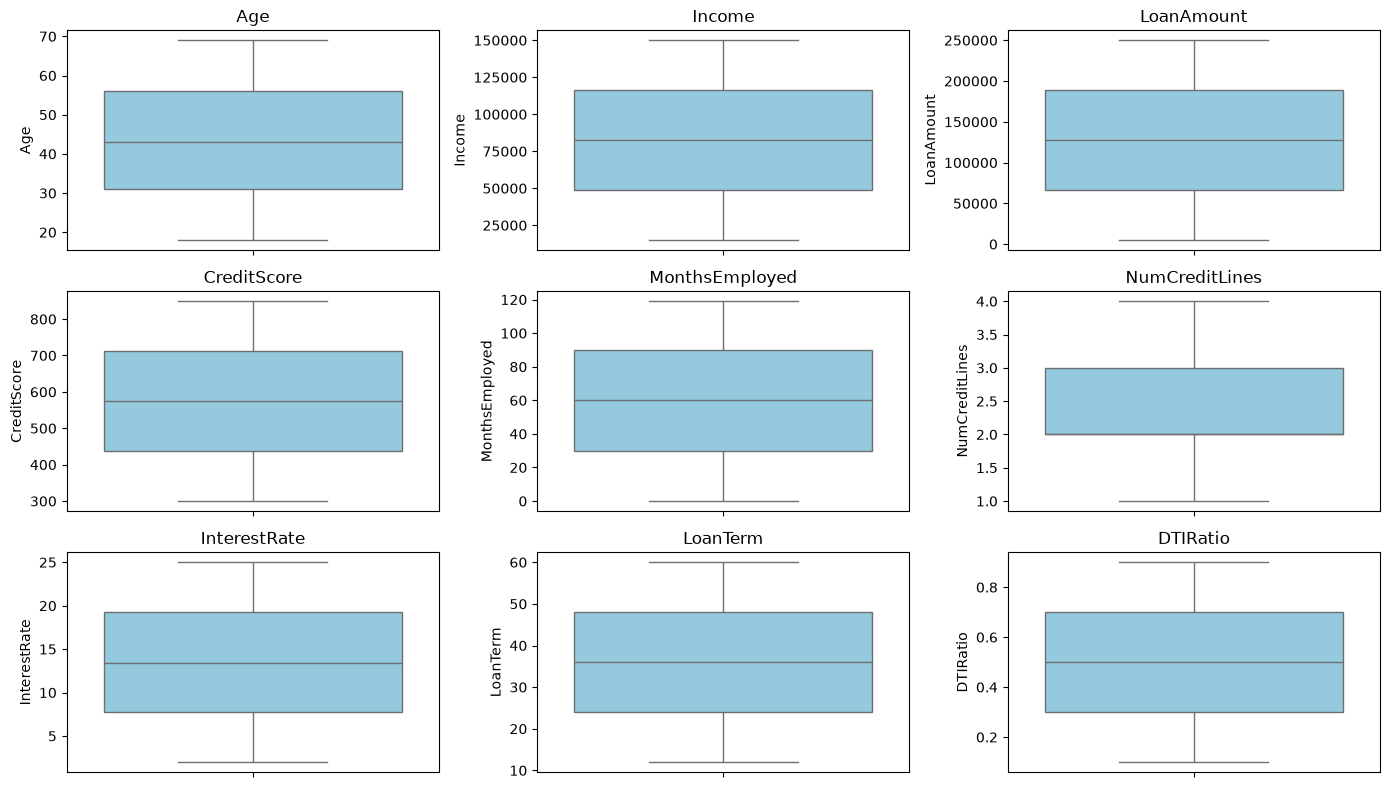

In [15]:
# Boxplots to see outliers visually
plt.figure(figsize=(14, 8))
for i, col in enumerate(num_cols, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(y=df[col], color='skyblue')
    plt.title(col)
plt.tight_layout()
plt.show()

**Result:** There are no outliers, and all values are in a realistic range (Age 18-69, CreditScore 300-850, etc.), so we do not remove any rows.

## 10. Check the target column (Default)
`0` = loan repaid, `1` = loan defaulted.

In [16]:
print(df['Default'].value_counts())
print()
print((df['Default'].value_counts(normalize=True) * 100).round(2))

Default
0    225694
1     29653
Name: count, dtype: int64

Default
0    88.39
1    11.61
Name: proportion, dtype: float64


## 11. Save the cleaned data

In [17]:
df.to_csv('Loan_default_cleaned.csv', index=False)
print('Cleaned file saved! Final shape:', df.shape)

Cleaned file saved! Final shape: (255347, 17)


### Summary
- No missing values, no duplicates
- Dropped `LoanID`
- No outliers to remove
- Saved as `Loan_default_cleaned.csv`

**Next:** open `2_Data_Visualization.ipynb`